In [1]:
%load_ext autoreload
%autoreload 2

# I. Modeling

Since our model is designed to encode the attributes of each entity (**type, size, color, and orientation angle**) we adopt a **multi-task CNN encoder architecture**. 

The encoder is jointly trained to predict these attributes from the visual input (crops) and to learn a compact **latent representation**. 

This latent vector will be combined with the entity’s **spatial and structural information** (**problem ID, panel ID, and bounding boxes**).

The resulting feature representation is then provided to the **graph construction module**, which uses these attributes to construct the graph representation that will ultimately be processed by the **GNN**.



## 1. Visual Encoder (CNN)

we choose to use a multi-task CNN architecture 
<div align="center">
  <img src="../assets/images/MT-CNN_GB.drawio.png" alt="Alt text">
</div>

**Training the model**

In [53]:
from hri_gnn.training import train

DATASET_NAME = "raven-20000"
PERCENTAGE_TO_USE = 0.01
NB_EPOCHS = 35
CHECK_FREQUENCY = 5
BATCH_SIZE = 5
LEARNING_RATE = 1e-4

training_history, validation_results ,model_training_time = train.run_training(
                                                                    DATASET_NAME,
                                                                    PERCENTAGE_TO_USE,
                                                                    NB_EPOCHS,
                                                                    CHECK_FREQUENCY,
                                                                    BATCH_SIZE,
                                                                    LEARNING_RATE
                                                                    )

Device : cuda
  GPU : NVIDIA GeForce RTX 5060 Laptop GPU

Loading dataset : raven-20000
  Percentage to use : 1.0%

Batch size : 5
Train dataset loaded : 814 problems
Val dataset loaded : 271 problems
Test dataset loaded : 271 problems

Modele : RavenCnnEncoder (164,638 parametres)

Optimizer : Adam
 Learning rate : 0.0001
 Loss : CompositeLoss 
 Metrics : CompositeMetric
epochs=35, batch_size=5, lr=0.0001
start training model: RavenCnnEncoder...


  0%|          | 0/35 [00:00<?, ?it/s]

Epoque 1/35: 
- Train (Test) losses: loss: 7.1049 (6.0957) - loss_type: 1.5641 (1.3262) - loss_size: 1.4393 (1.0879) - loss_color: 2.0164 (1.7263) - loss_angle: 2.0851 (1.9553) - 
- Train (Test) Metrics :accuracy: 0.2814 (0.3895) - precision: 0.2626 (0.4107) - recall: 0.2814 (0.3895) - f1: 0.2238 (0.3435) - accuracy_type: 0.3229 (0.4439) - accuracy_size: 0.4152 (0.5498) - accuracy_color: 0.2195 (0.3306) - accuracy_angle: 0.1680 (0.2338) - precision_type: 0.3279 (0.4399) - precision_size: 0.4101 (0.5611) - precision_color: 0.1577 (0.3364) - precision_angle: 0.1547 (0.3055) - recall_type: 0.3229 (0.4439) - recall_size: 0.4152 (0.5498) - recall_color: 0.2195 (0.3306) - recall_angle: 0.1680 (0.2338) - f1_type: 0.2747 (0.4027) - f1_size: 0.3558 (0.4951) - f1_color: 0.1457 (0.2827) - f1_angle: 0.1189 (0.1934) - 
Epoque 2/35: 
- Train (Test) losses: loss: 5.2776 (4.3714) - loss_type: 1.1826 (0.9707) - loss_size: 0.8858 (0.6764) - loss_color: 1.4352 (1.1975) - loss_angle: 1.7740 (1.5269) - 
- 

Validating the model...:   0%|          | 0/55 [00:00<?, ?it/s]


Validation finished!....
Number of crops: 10782 | Number of batches: 55


  RESULTS ON VALIDATION SET  
 Number: 
  - Crops   : 10782 
  - Batches : 55
  Loss   : 1.0541
  Accuracy : 89.84%
  Precision           : 0.9010
  Recall           : 0.8984
  F1 score          : 0.8880
-------------- DETAILED LOSSES ---------------
  Type Loss    : 0.0209
  Size Loss    : 0.0503
  Color Loss   : 0.0960
  Angle Loss   : 0.8869
------------- DETAILED ACCURACIES -------------
  Type Accuracy : 99.75%
  Size Accuracy : 98.99%
  Color Accuracy : 97.57%
  Angle Accuracy : 63.04%
-------------- DETAILED PRECISIONS -------------
  Type Precision     : 0.9980
  Size Precision     : 0.9866
  Color Precision    : 0.9714
  Angle Precision    : 0.6479
-------------- DETAILED RECALLS ---------------
  Type Recall     : 0.9975
  Size Recall     : 0.9899
  Color Recall    : 0.9757
  Angle Recall    : 0.6304
------------- DETAILED F1 SCORES --------------
  Type F1 score     : 0.9977
  Size F1 score     : 0.98

c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples


... (7 outputs left out)

c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples



[OK] Confusion matrix for val color saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\confusion_matrices\val\color_confusion_matrix.png

[OK] Confusion matrix for val angle saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\confusion_matrices\val\angle_confusion_matrix.png


c:\Users\dhias\DevTools\miniconda3\envs\nsc\Lib\site-packages\mlxtend\plotting\plot_confusion_matrix.py:102: RuntimeWarning: invalid value encountered in divide
  normed_conf_mat = conf_mat.astype("float") / total_samples



[OK] Confusion matrix for val overall saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\confusion_matrices\val\overall_confusion_matrix.png

[OK] type metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\type_metrics_curves.png

[OK] size metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\size_metrics_curves.png

[OK] color metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\color_metrics_curves.png

[OK] angle metric curves saved to C:\Users\dhias\workspaces\these\HRI-GNN\outputs\attributes_curves\angle_metrics_curves.png

[OK] Model saved : C:\Users\dhias\workspaces\these\HRI-GNN\outputs\models\raven_cnn_encoder_final.pth


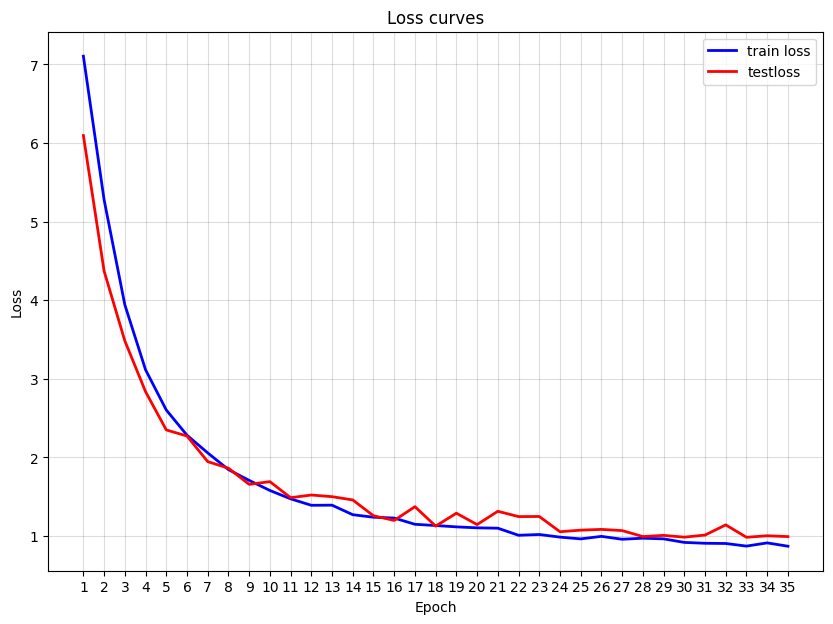

In [2]:
import json
import matplotlib.pyplot as plt
from hri_gnn.utils.paths import get_output_path

output_path = get_output_path()

with open(output_path/'training_history.json', 'r', encoding='utf-8') as file:
    data_hist = json.load(file)


epochs = range(1,len(data_hist['train_loss'])+1)

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot()
ax.plot(epochs, data_hist[f'train_loss'],color="blue",linewidth=2, label=f'train loss')
ax.plot(epochs, data_hist[f'test_loss'],color="red",linewidth=2, label=f'testloss')
ax.set_title(f'Loss curves')
ax.set_xlabel('Epoch')
ax.set_ylabel('Loss')
ax.set_xticks(epochs)
ax.legend()
ax.grid(True, alpha=0.2, color='#555')

In [3]:
# Training time

training_time = data_hist["training_session_time_seconds"]
minutes, seconds = divmod(training_time, 60)
hours ,minutes = divmod(minutes,60)
print(f"Training session took : {int(hours)}h {int(minutes)}m {int(seconds)}s")

Training session took : 2h 20m 27s


In [4]:
import json
from hri_gnn.utils.paths import get_output_path
from hri_gnn.training.train import print_validation_results

output_path = get_output_path()

with open(output_path/'validation_results.json', 'r', encoding='utf-8') as file:
    data_validation = json.load(file)

print_validation_results(data_validation)



  RESULTS ON VALIDATION SET  
 Number: 
  - Crops   : 10782 
  - Batches : 55
  Loss   : 1.0541
  Accuracy : 89.84%
  Precision           : 0.9010
  Recall           : 0.8984
  F1 score          : 0.8880
-------------- DETAILED LOSSES ---------------
  Type Loss    : 0.0209
  Size Loss    : 0.0503
  Color Loss   : 0.0960
  Angle Loss   : 0.8869
------------- DETAILED ACCURACIES -------------
  Type Accuracy : 99.75%
  Size Accuracy : 98.99%
  Color Accuracy : 97.57%
  Angle Accuracy : 63.04%
-------------- DETAILED PRECISIONS -------------
  Type Precision     : 0.9980
  Size Precision     : 0.9866
  Color Precision    : 0.9714
  Angle Precision    : 0.6479
-------------- DETAILED RECALLS ---------------
  Type Recall     : 0.9975
  Size Recall     : 0.9899
  Color Recall    : 0.9757
  Angle Recall    : 0.6304
------------- DETAILED F1 SCORES --------------
  Type F1 score     : 0.9977
  Size F1 score     : 0.9871
  Color F1 score    : 0.9697
  Angle F1 score    : 0.5973


## 2. Make some predictions

### 2.1 Graph builder


In [1]:
import random 

import torch 

from hri_gnn.datasets import raven_flat_collate
from torch.utils.data import DataLoader
from hri_gnn.datasets import RavenDataset

torch.manual_seed(42)
random.seed(42)

val_dataset_raven_100 = RavenDataset(
    dataset='raven-100',
    split='val',
    percentage_limit=0.1
)

val_dataloader = DataLoader(
    dataset=val_dataset_raven_100,
    batch_size=10,
    shuffle=False,
    collate_fn=raven_flat_collate
)

In [2]:
# first batch from the dataloader
import torch 
from  itertools import islice

count = 0
for batch in val_dataloader:
    count+= 1
    numb_prblm= torch.stack([batch[5],batch[6]]).unique(dim=-1).shape[1]
    problem_ids = [(k,i,j) for i,j,k in zip(torch.stack([batch[5],batch[6], batch[7]]).unique(dim=-1)[0].tolist(), torch.stack([batch[5],batch[6],batch[7]]).unique(dim=-1)[1].tolist(), torch.stack([batch[5],batch[6],batch[7]]).unique(dim=-1)[2].tolist())  ] 
    print(f"batch number: {count}, problems count: {numb_prblm}, (batch_id, config_id, prblm_id): {sorted(problem_ids)}")
print(f"dataset length: {len(val_dataset_raven_100)}")
print(f"dataloader length: {count}")


batch number: 1, problems count: 10, (batch_id, config_id, prblm_id): [(0, 1, 56), (1, 0, 46), (2, 3, 66), (3, 3, 26), (4, 2, 87), (5, 1, 7), (6, 1, 46), (7, 6, 97), (8, 1, 26), (9, 5, 56)]
batch number: 2, problems count: 4, (batch_id, config_id, prblm_id): [(0, 0, 56), (1, 0, 47), (2, 1, 27), (3, 2, 7)]
dataset length: 14
dataloader length: 2


In [ ]:
number_of_entities

In [11]:
from collections import defaultdict
import itertools
first_batch = list(itertools.islice(iter(val_dataloader), 0,1))[0]

# Number of crops is the number of entities
number_of_entities = first_batch[0].shape[0]

# regroups entities by problem, the problem is identified by (batch_id, config_id, problem_id)
problems = defaultdict(list)

for i in range(number_of_entities):
    entity = {'id': i, 'panel_id':first_batch[3][i].item() ,'component_id':first_batch[4][i].item() , 'attributes':first_batch[1][i], 'bbox':first_batch[2][i]}
    key_problem = (first_batch[7][i].item(), first_batch[5][i].item(), first_batch[6][i].item())
    
    nested_tree = defaultdict(lambda: defaultdict(list))
    p_id = first_batch[3][i].item()
    c_id = first_batch[4][i].item()
    nested_tree[p_id][c_id].append(entity)

    problems[key_problem].append({p_id: dict(components) for p_id, components in nested_tree.items()})

# Print the result
import pprint
pprint.pprint(dict(problems))


{(0, 1, 56): [{0: {0: [{'attributes': tensor([2., 0., 0., 4.]),
                        'bbox': tensor([0.7500, 0.2500, 0.5000, 0.5000]),
                        'component_id': 0,
                        'id': 0,
                        'panel_id': 0}]}},
              {0: {0: [{'attributes': tensor([2., 0., 0., 4.]),
                        'bbox': tensor([0.7500, 0.7500, 0.5000, 0.5000]),
                        'component_id': 0,
                        'id': 1,
                        'panel_id': 0}]}},
              {1: {0: [{'attributes': tensor([1., 5., 0., 4.]),
                        'bbox': tensor([0.2500, 0.2500, 0.5000, 0.5000]),
                        'component_id': 0,
                        'id': 2,
                        'panel_id': 1}]}},
              {1: {0: [{'attributes': tensor([1., 5., 0., 4.]),
                        'bbox': tensor([0.2500, 0.7500, 0.5000, 0.5000]),
                        'component_id': 0,
                        'id': 3,
               

In [6]:
transformed_data = {}

for key, entity_list in problems.items():
    # Setup a tree structure: panel_id -> component_id -> list of entities
    nested_tree = defaultdict(lambda: defaultdict(list))
    
    for entity in entity_list:
        p_id = entity['panel_id']
        c_id = entity['component_id']
        
        # Append the entity to the correct component list inside the correct panel
        nested_tree[p_id][c_id].append(entity)
        
    # Convert defaultdict back to standard dict for clean output
    transformed_data[key] = {
        p_id: dict(components) for p_id, components in nested_tree.items()
    }

# Print the result
import pprint
pprint.pprint(transformed_data)

{(0, 1, 56): {0: {0: [{'attributes': tensor([2., 0., 0., 4.]),
                       'bbox': tensor([0.7500, 0.2500, 0.5000, 0.5000]),
                       'component_id': 0,
                       'id': 0,
                       'panel_id': 0},
                      {'attributes': tensor([2., 0., 0., 4.]),
                       'bbox': tensor([0.7500, 0.7500, 0.5000, 0.5000]),
                       'component_id': 0,
                       'id': 1,
                       'panel_id': 0}]},
              1: {0: [{'attributes': tensor([1., 5., 0., 4.]),
                       'bbox': tensor([0.2500, 0.2500, 0.5000, 0.5000]),
                       'component_id': 0,
                       'id': 2,
                       'panel_id': 1},
                      {'attributes': tensor([1., 5., 0., 4.]),
                       'bbox': tensor([0.2500, 0.7500, 0.5000, 0.5000]),
                       'component_id': 0,
                       'id': 3,
                       'panel_id': 1}]},


In [90]:
# load the saved model 
import torch
from hri_gnn.utils.paths import get_output_path
from hri_gnn.models.cnn_encoder import RavenCnnEncoder

output_path = get_output_path()

raven_encoder = RavenCnnEncoder()

raven_encoder.load_state_dict(torch.load(f=output_path/'models'/'raven_cnn_encoder_final.pth'))

<All keys matched successfully>

In [93]:
# make prediction 
raven_encoder.eval()
model_outputs = []
with torch.inference_mode():
    for batch in val_dataloader:
        model_outputs.append(raven_encoder(batch[0]))

model_output = model_outputs[0]

In [108]:
import random
import matplotlib.pyplot as plt
from hri_gnn.config.const import ENTITY_ATTRIBUTES
from hri_gnn.config.const import Configuration
from hri_gnn.visualization import oracle


crop_number = random.randint(0,model_output['pred_type_logits'].size(0))
encoded_predicted_type  = model_output['pred_type_logits'].argmax(dim=1)[crop_number]
encoded_predicted_size  = model_output['pred_size_logits'].argmax(dim=1)[crop_number]
encoded_predicted_color = model_output['pred_color_logits'].argmax(dim=1)[crop_number]
encoded_predicted_angle = model_output['pred_angle_logits'].argmax(dim=1)[crop_number]

decoded_predicted_type  =  ENTITY_ATTRIBUTES['type'][encoded_predicted_type]
decoded_predicted_size  =  ENTITY_ATTRIBUTES['size'][encoded_predicted_size]
decoded_predicted_color =  ENTITY_ATTRIBUTES['color'][encoded_predicted_color]
decoded_predicted_angle =  ENTITY_ATTRIBUTES['angle'][encoded_predicted_angle]

print(f"Predicted Crop Type:  {decoded_predicted_type}")
print(f"Predicted Crop Size:  {decoded_predicted_size}")
print(f"Predicted Crop color: {decoded_predicted_color}")
print(f"Predicted Crop Angle: {decoded_predicted_angle}")

plt.imshow(batch[0][crop_number].permute(2,1,0), cmap="gray")
title =f" NB: {crop_number} | "
encoded_real_type = ENTITY_ATTRIBUTES['type'][int(batch[1][crop_number].tolist()[0])] 
encoded_real_size = ENTITY_ATTRIBUTES['size'][int(batch[1][crop_number].tolist()[1])] 
encoded_real_color= ENTITY_ATTRIBUTES['color'][int(batch[1][crop_number].tolist()[2])]
encoded_real_angle= ENTITY_ATTRIBUTES['angle'][int(batch[1][crop_number].tolist()[3])]

title +=f"Type:   {encoded_real_type } | "
title +=f"size:   {encoded_real_size } | "
title +=f"color:  {encoded_real_color} | "
title +=f"angle:  {encoded_real_angle} \n"
title +=f"Prb_id: {batch[6][crop_number].item()}| Pnl_id: {batch[3][crop_number].item()}| cmp: {batch[4][crop_number].item()}\n"
title +=f"Cfg: {Configuration.all()[batch[5][crop_number].item()]}"

plt.title(title)
plt.show()

Predicted Crop Type:  pentagon
Predicted Crop Size:  0.7
Predicted Crop color: 255
Predicted Crop Angle: 0


NameError: name 'batch' is not defined

In [24]:
# print(f"btach item {0}: crops               ,shape: {batch[0].shape}")
# print(f"batch item {1}: attributes          ,shape: {batch[1].shape}")
# print(f"btach item {2}: bbox                ,shape: {batch[2].shape}")
# print(f"btach item {3}: panel indices       ,shape: {batch[3].shape}")
# print(f"btach item {4}: component indices   ,shape: {batch[4].shape}")
# print(f"btach item {5}: config indices      ,shape: {batch[5].dtype}")
# print(f"btach item {6}: problems indices    ,shape: {batch[6].shape}")
# print(f"btach item {7}: indices             ,shape: {batch[7].shape}")

btach item 0: crops               ,shape: torch.Size([350, 1, 80, 80])
batch item 1: attributes          ,shape: torch.Size([350, 4])
btach item 2: bbox                ,shape: torch.Size([350, 4])
btach item 3: panel indices       ,shape: torch.Size([350])
btach item 4: component indices   ,shape: torch.Size([350])
btach item 5: config indices      ,shape: torch.int64
btach item 6: problems indices    ,shape: torch.Size([350])
btach item 7: indices             ,shape: torch.Size([350])


In [97]:
# from hri_gnn.models import graph_builder
# from hri_gnn.config.const import Configuration

# nb_crop = random.randint(0,model_output['pred_type_logits'].size(0))

# bbox = batch[2][nb_crop].tolist()
# config_id = batch[5][nb_crop].item() 
# component_id = batch[4][nb_crop].item()
# slot = graph_builder.bbox_to_slot(bbox=bbox, config_id=config_id, component_id=component_id)
# print(f"Configuration: {Configuration.all()[config_id]}")
# print(f"Component_id : {component_id}")
# print(f"bbox: {bbox}")
# print(f"slot: {slot}")



Configuration: distribute_nine
Component_id : 0
bbox: [0.1599999964237213, 0.5, 0.33000001311302185, 0.33000001311302185]
slot: 1


In [98]:
# from hri_gnn.models import graph_builder

# nb_crop = random.randint(0,model_output['pred_type_logits'].size(0))

# panel_id = batch[3][nb_crop].item()

# row, col = graph_builder.ctx_panel_to_row_col(panel_id)
# print(f"panel_id: {panel_id}, belongs to (row,col) :{row,col}")


panel_id: 3, belongs to (row,col) :(1, 0)


In [99]:
# from hri_gnn.models import graph_builder

# nb_crop = random.randint(0,model_output['pred_type_logits'].size(0))

# panel_id = batch[3][nb_crop].item()

# row_groups = graph_builder.get_row_groups(panel_id)

# print(f"panel_id: {panel_id}, row_groups :{row_groups}")




panel_id: 13, row_groups :[[0, 1, 2], [3, 4, 5], [6, 7, 13]]


In [101]:
# from hri_gnn.models import graph_builder

# nb_crop = random.randint(0,model_output['pred_type_logits'].size(0))

# panel_id = batch[3][nb_crop].item()

# col_groups = graph_builder.get_col_groups(panel_id)

# print(f"panel_id: {panel_id}, row_groups :{col_groups}")

panel_id: 8, row_groups :[[0, 3, 6], [1, 4, 7], [2, 5, 8]]


In [102]:
# from hri_gnn.models import graph_builder

# edges = graph_builder.build_directed_pair_edges(row_groups[0])

# print(f"first row groups: {row_groups[0]}")
# print(f"Edges: {edges}")

first row groups: [0, 1, 2]
Edges: [(0, 1, 'forward'), (1, 0, 'backward'), (0, 2, 'forward'), (2, 0, 'backward'), (1, 2, 'forward'), (2, 1, 'backward')]


In [202]:
batch = list(islice(val_dataloader, 0,9))[0]
flat_crops              = batch[0] # btach item 0:       crops        ,shape: [502, 1, 80, 80]
flat_attributes         = batch[1] # batch item 1:     attributes     ,shape: [502, 4]
flat_bboxes             = batch[2] # btach item 2:        bbox        ,shape: [502, 4]
flat_panel_indices      = batch[3] # btach item 3:    panel indices   ,shape: [502]
flat_component_indices  = batch[4] # btach item 4: component indices  ,shape: [502]
flat_config_indices     = batch[5] # btach item 5:   config indices   ,shape: [502]
flat_problem_indices    = batch[6] # btach item 6: problems indices   ,shape: [502]
flat_batch_indices      = batch[7] # btach item 7:        indices     ,shape: [502]

In [203]:
from hri_gnn.models import graph_builder
crop_groups_by_problem = graph_builder.group_crops_by_problem(flat_config_indices , flat_problem_indices , flat_batch_indices)
crop_groups_by_problem

{(6,
  86,
  0): tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17,
         18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31]),
 (6,
  16,
  1): tensor([32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49,
         50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63]),
 (3,
  96,
  2): tensor([64, 65, 66, 67, 68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81,
         82, 83, 84, 85, 86, 87, 88, 89, 90, 91, 92, 93, 94, 95]),
 (1,
  36,
  3): tensor([ 96,  97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109,
         110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 120, 121]),
 (4,
  67,
  4): tensor([122, 123, 124, 125, 126, 127, 128, 129, 130, 131, 132, 133, 134, 135,
         136, 137, 138, 139, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149,
         150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 160, 161, 162, 163,
         164, 165, 166, 167, 168, 169, 170, 171, 172, 173, 174, 175, 176, 177,
         1

In [149]:
from hri_gnn.config.const import Configuration
from hri_gnn.models import graph_builder
from itertools import islice



# get the second element of the dictionnary items
second_crop_group_by_problem = list(islice(crop_groups_by_problem.items(), 1,2))[0]
print(f"- Second crop_group_by_problem: \n{second_crop_group_by_problem}")

# Second item key
second_crop_group_by_problem_key = second_crop_group_by_problem[0]

config_id= second_crop_group_by_problem_key[0]
problem_id = second_crop_group_by_problem_key[1]
batch_id = second_crop_group_by_problem_key[2]

# config_id -> get configuratuion name 
config_name = Configuration.all()[config_id]

print(f" - (config, problem_id, batch_id) : {second_crop_group_by_problem_key}")
print(f" - Configuration {config_id} is: {config_name}\n - Problem id: {problem_id}\n - Batch id: {batch_id}")




- Second crop_group_by_problem: 
((4, 76, 1), tensor([32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49,
        50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 60, 61, 62, 63, 64, 65, 66, 67,
        68, 69, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 80, 81, 82, 83, 84, 85,
        86, 87, 88, 89, 90, 91]))
 - (config, problem_id, batch_id) : (4, 76, 1)
 - Configuration 4 is: in_distribute_four_out_center_single
 - Problem id: 76
 - Batch id: 1


In [39]:
second_crop_group_by_problem_value = second_crop_group_by_problem[1]
print(f" - crops indices of the problem id: {problem_id}\n of the config: {config_name}:\n{second_crop_group_by_problem_value}")
print(f" - Number of crops in this problem : {second_crop_group_by_problem_value.shape[0]}")

 - crops indices of the problem id: 56
 of the config: in_distribute_four_out_center_single:
tensor([ 67,  68,  69,  70,  71,  72,  73,  74,  75,  76,  77,  78,  79,  80,
         81,  82,  83,  84,  85,  86,  87,  88,  89,  90,  91,  92,  93,  94,
         95,  96,  97,  98,  99, 100, 101, 102, 103, 104, 105, 106, 107, 108,
        109, 110, 111, 112, 113])
 - Number of crops in this problem : 47


In [40]:
# Slots ids
crops_slots_ids = graph_builder.crop_slot_ids_by_problem(second_crop_group_by_problem_value, flat_bboxes, flat_config_indices,flat_component_indices)
print(f" - slot indices of these crops:\n{crops_slots_ids}")

 - slot indices of these crops:
tensor([0, 1, 0, 0, 0, 3, 0, 0, 2, 0, 3, 1, 0, 2, 0, 0, 2, 0, 0, 1, 3, 0, 0, 1,
        3, 0, 0, 2, 0, 0, 2, 0, 3, 0, 0, 2, 3, 0, 0, 0, 2, 0, 0, 2, 0, 0, 2])


In [41]:
from hri_gnn.models import graph_builder
entity_x, entity_meta, local_idx_map = graph_builder.build_entity_nodes(second_crop_group_by_problem_value, model_output, flat_panel_indices, flat_component_indices,flat_config_indices, crops_slots_ids)

print(f" - Entity Node (all crops in one problem represents an Entity Node )\n{entity_x}")
print(f" - Entity Node Meta data (flat_panel_ids, flat_component_ids, flat_config_ids and flat_slot_ids [calculated])\n{entity_meta}")
print(f" - Entity Node Local ids mapping (real_crop_id <-map-> node_local_crop_id )\n{local_idx_map}")

 - Entity Node (all crops in one problem represents an Entity Node )
tensor([[  0.0000,  84.0242,   0.0000,  ...,   4.5532,  -3.8752,   5.3949],
        [ 25.5719,  70.2062,   0.0000,  ...,   5.8413,  -2.3778,   6.3451],
        [  3.7031,  79.9268,   0.0000,  ...,   3.0553,  -2.4641,   3.4336],
        ...,
        [  6.1226,  96.5565,   0.0000,  ...,   4.2706,  -1.1025,   4.0656],
        [ 18.0381,  14.9668,   0.0000,  ..., -11.1132,  11.3421,  -9.3195],
        [ 34.5567,  44.0196,   0.0000,  ...,  -0.2026,  -4.3196,  -8.1068]])
 - Entity Node Meta data (flat_panel_ids, flat_component_ids, flat_config_ids and flat_slot_ids [calculated])
{'panel_id': tensor([ 0,  0,  1,  1,  2,  2,  3,  3,  3,  4,  4,  4,  5,  5,  5,  6,  6,  6,
         7,  7,  7,  8,  8,  8,  8,  9,  9,  9, 10, 10, 10, 11, 11, 11, 12, 12,
        12, 12, 13, 13, 13, 14, 14, 14, 15, 15, 15]), 'component_id': tensor([0, 1, 0, 1, 0, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1, 0, 1, 1,
        1, 0, 1, 1, 0, 1, 1,

In [42]:
from hri_gnn.models import graph_builder

intra_panel_entity_edge_index, intra_panel_entity_edge_attr = graph_builder.build_intra_panel_entity_edges(entity_meta,flat_bboxes, second_crop_group_by_problem_value)

print(f"intra panel entity edges indices (source/destination):\n{intra_panel_entity_edge_index}")
print(f"intra panel entity edges attributes: \n{intra_panel_entity_edge_attr}")
#for edge  in intra_panel_entity_edge_index:
for i in range(0,intra_panel_entity_edge_index.shape[1],2):
    id_src = intra_panel_entity_edge_index[0][i].item()
    id_dst = intra_panel_entity_edge_index[1][i].item()
    
    cmp_name_src = "OUT" if entity_meta['component_id'][id_src] == 0 else "IN"
    cmp_name_dst = "OUT" if entity_meta['component_id'][id_dst] == 0 else "IN"

    pnl_src = entity_meta['panel_id'][id_src]
    pnl_dst = entity_meta['panel_id'][id_dst]
    
    print(f"{id_src}<->{id_dst}, component: {cmp_name_src}<->{cmp_name_dst}, panel: {pnl_src}<->{pnl_dst}, attr: {intra_panel_entity_edge_attr[i].tolist()}<->{intra_panel_entity_edge_attr[i+1].tolist()}")

group_by_panel_and_component: 
defaultdict(<class 'list'>, {(0, 0): [0], (0, 1): [1], (1, 0): [2], (1, 1): [3], (2, 0): [4], (2, 1): [5], (3, 0): [6], (3, 1): [7, 8], (4, 0): [9], (4, 1): [10, 11], (5, 0): [12], (5, 1): [13, 14], (6, 0): [15], (6, 1): [16, 17], (7, 0): [18], (7, 1): [19, 20], (8, 0): [21], (8, 1): [22, 23, 24], (9, 0): [25], (9, 1): [26, 27], (10, 0): [28], (10, 1): [29, 30], (11, 0): [31], (11, 1): [32, 33], (12, 0): [34], (12, 1): [35, 36, 37], (13, 0): [38], (13, 1): [39, 40], (14, 0): [41], (14, 1): [42, 43], (15, 0): [44], (15, 1): [45, 46]})
intra panel entity edges indices (source/destination):
tensor([[ 7,  8, 10, 11, 13, 14, 16, 17, 19, 20, 22, 23, 22, 24, 23, 24, 26, 27,
         29, 30, 32, 33, 35, 36, 35, 37, 36, 37, 39, 40, 42, 43, 45, 46],
        [ 8,  7, 11, 10, 14, 13, 17, 16, 20, 19, 23, 22, 24, 22, 24, 23, 27, 26,
         30, 29, 33, 32, 36, 35, 37, 35, 37, 36, 40, 39, 43, 42, 46, 45]])
intra panel entity edges attributes: 
tensor([[ 0.1600,  0.0000

In [43]:
from itertools import combinations, islice

from hri_gnn.models import graph_builder

panel_to_enties = graph_builder.group_entities_by_panel(entity_meta)
print(f"Local entity panel_ids mapped groups:\n {panel_to_enties}")

Local entity panel_ids mapped groups:
 defaultdict(<class 'list'>, {0: [0, 1], 1: [2, 3], 2: [4, 5], 3: [6, 7, 8], 4: [9, 10, 11], 5: [12, 13, 14], 6: [15, 16, 17], 7: [18, 19, 20], 8: [21, 22, 23, 24], 9: [25, 26, 27], 10: [28, 29, 30], 11: [31, 32, 33], 12: [34, 35, 36, 37], 13: [38, 39, 40], 14: [41, 42, 43], 15: [44, 45, 46]})


In [44]:
from hri_gnn.models import graph_builder

all_groups = graph_builder.get_all_groups(include_columns=False)

all_groups

# for index, group in enumerate(all_groups):
#     print(f"group numer: {index} is: {group}")

[[0, 1, 2],
 [3, 4, 5],
 [6, 7, 8],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 9],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 10],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 11],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 12],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 13],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 14],
 [0, 1, 2],
 [3, 4, 5],
 [6, 7, 15]]

In [45]:
from hri_gnn.models import graph_builder

inter_panel_entity_edge_index, inter_panel_entity_edge_attr = graph_builder.build_inter_panel_entity_edges(entity_meta, entity_x, panel_to_enties, all_groups)

print(f"entity local id<-endge->entity local id indices:\n{inter_panel_entity_edge_index}")
print(f"entity local id<-endge->entity local id attributes: \n{inter_panel_entity_edge_attr}")

entity local id<-endge->entity local id indices:
tensor([[ 0,  2,  0,  4,  2,  4,  6,  9,  7, 14,  8, 13,  6, 12,  9, 12, 15, 18,
         17, 22, 15, 21, 19, 23, 20, 24, 18, 21,  0,  2,  0,  4,  2,  4,  6,  9,
          7, 14,  8, 13,  6, 12,  9, 12, 15, 18, 17, 26, 16, 27, 15, 25, 18, 25,
          0,  2,  0,  4,  2,  4,  6,  9,  7, 14,  8, 13,  6, 12,  9, 12, 15, 18,
         17, 29, 16, 30, 15, 28, 18, 28,  0,  2,  0,  4,  2,  4,  6,  9,  7, 14,
          8, 13,  6, 12,  9, 12, 15, 18, 17, 33, 15, 31, 20, 32, 18, 31,  0,  2,
          0,  4,  2,  4,  6,  9,  7, 14,  8, 13,  6, 12,  9, 12, 15, 18, 17, 37,
         16, 35, 15, 34, 20, 36, 18, 34,  0,  2,  0,  4,  2,  4,  6,  9,  7, 14,
          8, 13,  6, 12,  9, 12, 15, 18, 17, 39, 16, 40, 15, 38, 18, 38,  0,  2,
          0,  4,  2,  4,  6,  9,  7, 14,  8, 13,  6, 12,  9, 12, 15, 18, 17, 42,
         16, 43, 15, 41, 18, 41,  0,  2,  0,  4,  2,  4,  6,  9,  7, 14,  8, 13,
          6, 12,  9, 12, 15, 18, 17, 45, 16, 46, 15, 44, 18,

In [46]:
from hri_gnn.models import graph_builder

panel_x, panel_keys, panel_local_idx_map, panel_to_local_entities = graph_builder.build_panel_nodes(entity_meta, entity_x)

print(f"panel_x :\n{panel_x}, shape {panel_x.shape}")
print(f"panel_keys : \n{panel_keys}")
print(f"panel_local_idx_map :\n{panel_local_idx_map}")
print(f"panel_to_local_entities :\n{panel_to_local_entities}")

panel_x :
tensor([[ 0.0000, 84.0242,  0.0000,  ...,  0.0000,  1.0000,  0.0000],
        [25.5719, 70.2062,  0.0000,  ...,  0.0000,  1.0000,  1.0000],
        [ 3.7031, 79.9268,  0.0000,  ...,  0.0000,  1.0000,  0.0000],
        ...,
        [22.1187, 86.7696,  0.0000,  ...,  0.0000,  2.0000,  1.0000],
        [ 6.1226, 96.5565,  0.0000,  ...,  0.0000,  1.0000,  0.0000],
        [26.2974, 29.4932,  0.0000,  ...,  0.0000,  2.0000,  1.0000]]), shape torch.Size([32, 105])
panel_keys : 
[(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1), (4, 0), (4, 1), (5, 0), (5, 1), (6, 0), (6, 1), (7, 0), (7, 1), (8, 0), (8, 1), (9, 0), (9, 1), (10, 0), (10, 1), (11, 0), (11, 1), (12, 0), (12, 1), (13, 0), (13, 1), (14, 0), (14, 1), (15, 0), (15, 1)]
panel_local_idx_map :
{(0, 0): 0, (0, 1): 1, (1, 0): 2, (1, 1): 3, (2, 0): 4, (2, 1): 5, (3, 0): 6, (3, 1): 7, (4, 0): 8, (4, 1): 9, (5, 0): 10, (5, 1): 11, (6, 0): 12, (6, 1): 13, (7, 0): 14, (7, 1): 15, (8, 0): 16, (8, 1): 17, (9, 0): 18, (9,

In [47]:
from hri_gnn.models import graph_builder
inter_panel_panel_edge_index, inter_panel_panel_edge_attr = graph_builder.build_inter_panel_panel_edges(panel_to_local_entities, panel_local_idx_map, entity_meta, all_groups)

print(f"panel local id<-endge->panel local id indices:\n{inter_panel_panel_edge_index}")
print(f"panel local id<-endge->panel local id attributes: \n{inter_panel_panel_edge_attr}")

panel local id<-endge->panel local id indices:
tensor([[ 0,  2,  0,  4,  2,  4,  1,  3,  1,  5,  3,  5,  6,  8,  6, 10,  8, 10,
          7,  9,  7, 11,  9, 11, 12, 14, 12, 16, 14, 16, 13, 15, 13, 17, 15, 17,
          0,  2,  0,  4,  2,  4,  1,  3,  1,  5,  3,  5,  6,  8,  6, 10,  8, 10,
          7,  9,  7, 11,  9, 11, 12, 14, 12, 18, 14, 18, 13, 15, 13, 19, 15, 19,
          0,  2,  0,  4,  2,  4,  1,  3,  1,  5,  3,  5,  6,  8,  6, 10,  8, 10,
          7,  9,  7, 11,  9, 11, 12, 14, 12, 20, 14, 20, 13, 15, 13, 21, 15, 21,
          0,  2,  0,  4,  2,  4,  1,  3,  1,  5,  3,  5,  6,  8,  6, 10,  8, 10,
          7,  9,  7, 11,  9, 11, 12, 14, 12, 22, 14, 22, 13, 15, 13, 23, 15, 23,
          0,  2,  0,  4,  2,  4,  1,  3,  1,  5,  3,  5,  6,  8,  6, 10,  8, 10,
          7,  9,  7, 11,  9, 11, 12, 14, 12, 24, 14, 24, 13, 15, 13, 25, 15, 25,
          0,  2,  0,  4,  2,  4,  1,  3,  1,  5,  3,  5,  6,  8,  6, 10,  8, 10,
          7,  9,  7, 11,  9, 11, 12, 14, 12, 26, 14, 26, 13, 1

In [50]:
panel_to_local_entities

defaultdict(list,
            {(0, 0): [0],
             (0, 1): [1],
             (1, 0): [2],
             (1, 1): [3],
             (2, 0): [4],
             (2, 1): [5],
             (3, 0): [6],
             (3, 1): [7, 8],
             (4, 0): [9],
             (4, 1): [10, 11],
             (5, 0): [12],
             (5, 1): [13, 14],
             (6, 0): [15],
             (6, 1): [16, 17],
             (7, 0): [18],
             (7, 1): [19, 20],
             (8, 0): [21],
             (8, 1): [22, 23, 24],
             (9, 0): [25],
             (9, 1): [26, 27],
             (10, 0): [28],
             (10, 1): [29, 30],
             (11, 0): [31],
             (11, 1): [32, 33],
             (12, 0): [34],
             (12, 1): [35, 36, 37],
             (13, 0): [38],
             (13, 1): [39, 40],
             (14, 0): [41],
             (14, 1): [42, 43],
             (15, 0): [44],
             (15, 1): [45, 46]})

In [51]:
panel_local_idx_map.keys()

dict_keys([(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1), (3, 0), (3, 1), (4, 0), (4, 1), (5, 0), (5, 1), (6, 0), (6, 1), (7, 0), (7, 1), (8, 0), (8, 1), (9, 0), (9, 1), (10, 0), (10, 1), (11, 0), (11, 1), (12, 0), (12, 1), (13, 0), (13, 1), (14, 0), (14, 1), (15, 0), (15, 1)])

In [52]:
for i in range(0,inter_panel_panel_edge_index.shape[1],2):
    id_src = inter_panel_panel_edge_index[0][i].item()
    id_dst = inter_panel_panel_edge_index[1][i].item()

    pnl_src = [k for (k,v) in panel_local_idx_map.items() if v == id_src][0]

    pnl_dst = [k for (k,v) in panel_local_idx_map.items() if v == id_dst][0]

    cmp_name_src = "OUT" if pnl_src[1] == 0 else "IN"
    cmp_name_dst = "OUT" if pnl_dst[1] == 0 else "IN"

    print(f"{id_src}<->{id_dst}, c: {cmp_name_src}<->{cmp_name_dst}, p : {pnl_src}<->{pnl_dst}, attr: {inter_panel_panel_edge_attr[i].tolist()}<->{inter_panel_panel_edge_attr[i+1].tolist()}")

0<->2, c: OUT<->OUT, p : (0, 0)<->(1, 0), attr: [1.0, 0.0, 1.0, 0.0, 0.0]<->[-1.0, 0.0, 1.0, 0.0, 0.0]
0<->4, c: OUT<->OUT, p : (0, 0)<->(2, 0), attr: [1.0, 0.0, 1.0, 0.0, 0.0]<->[-1.0, 0.0, 1.0, 0.0, 0.0]
2<->4, c: OUT<->OUT, p : (1, 0)<->(2, 0), attr: [1.0, 0.0, 1.0, 0.0, 0.0]<->[-1.0, 0.0, 1.0, 0.0, 0.0]
1<->3, c: IN<->IN, p : (0, 1)<->(1, 1), attr: [1.0, 0.0, 0.0, 1.0, 1.0]<->[-1.0, 0.0, 0.0, 1.0, 1.0]
1<->5, c: IN<->IN, p : (0, 1)<->(2, 1), attr: [1.0, 0.0, 0.0, 1.0, 1.0]<->[-1.0, 0.0, 0.0, 1.0, 1.0]
3<->5, c: IN<->IN, p : (1, 1)<->(2, 1), attr: [1.0, 0.0, 0.0, 1.0, 1.0]<->[-1.0, 0.0, 0.0, 1.0, 1.0]
6<->8, c: OUT<->OUT, p : (3, 0)<->(4, 0), attr: [1.0, 0.0, 1.0, 0.0, 0.0]<->[-1.0, 0.0, 1.0, 0.0, 0.0]
6<->10, c: OUT<->OUT, p : (3, 0)<->(5, 0), attr: [1.0, 0.0, 1.0, 0.0, 0.0]<->[-1.0, 0.0, 1.0, 0.0, 0.0]
8<->10, c: OUT<->OUT, p : (4, 0)<->(5, 0), attr: [1.0, 0.0, 1.0, 0.0, 0.0]<->[-1.0, 0.0, 1.0, 0.0, 0.0]
7<->9, c: IN<->IN, p : (3, 1)<->(4, 1), attr: [1.0, 0.0, 0.0, 2.0, 2.0]<->[-1

Problem dataset: raven-100
Problem configuration: in_distribute_four_out_center_single
Problem id: 46
Problem split: val

The correct answer is: 6


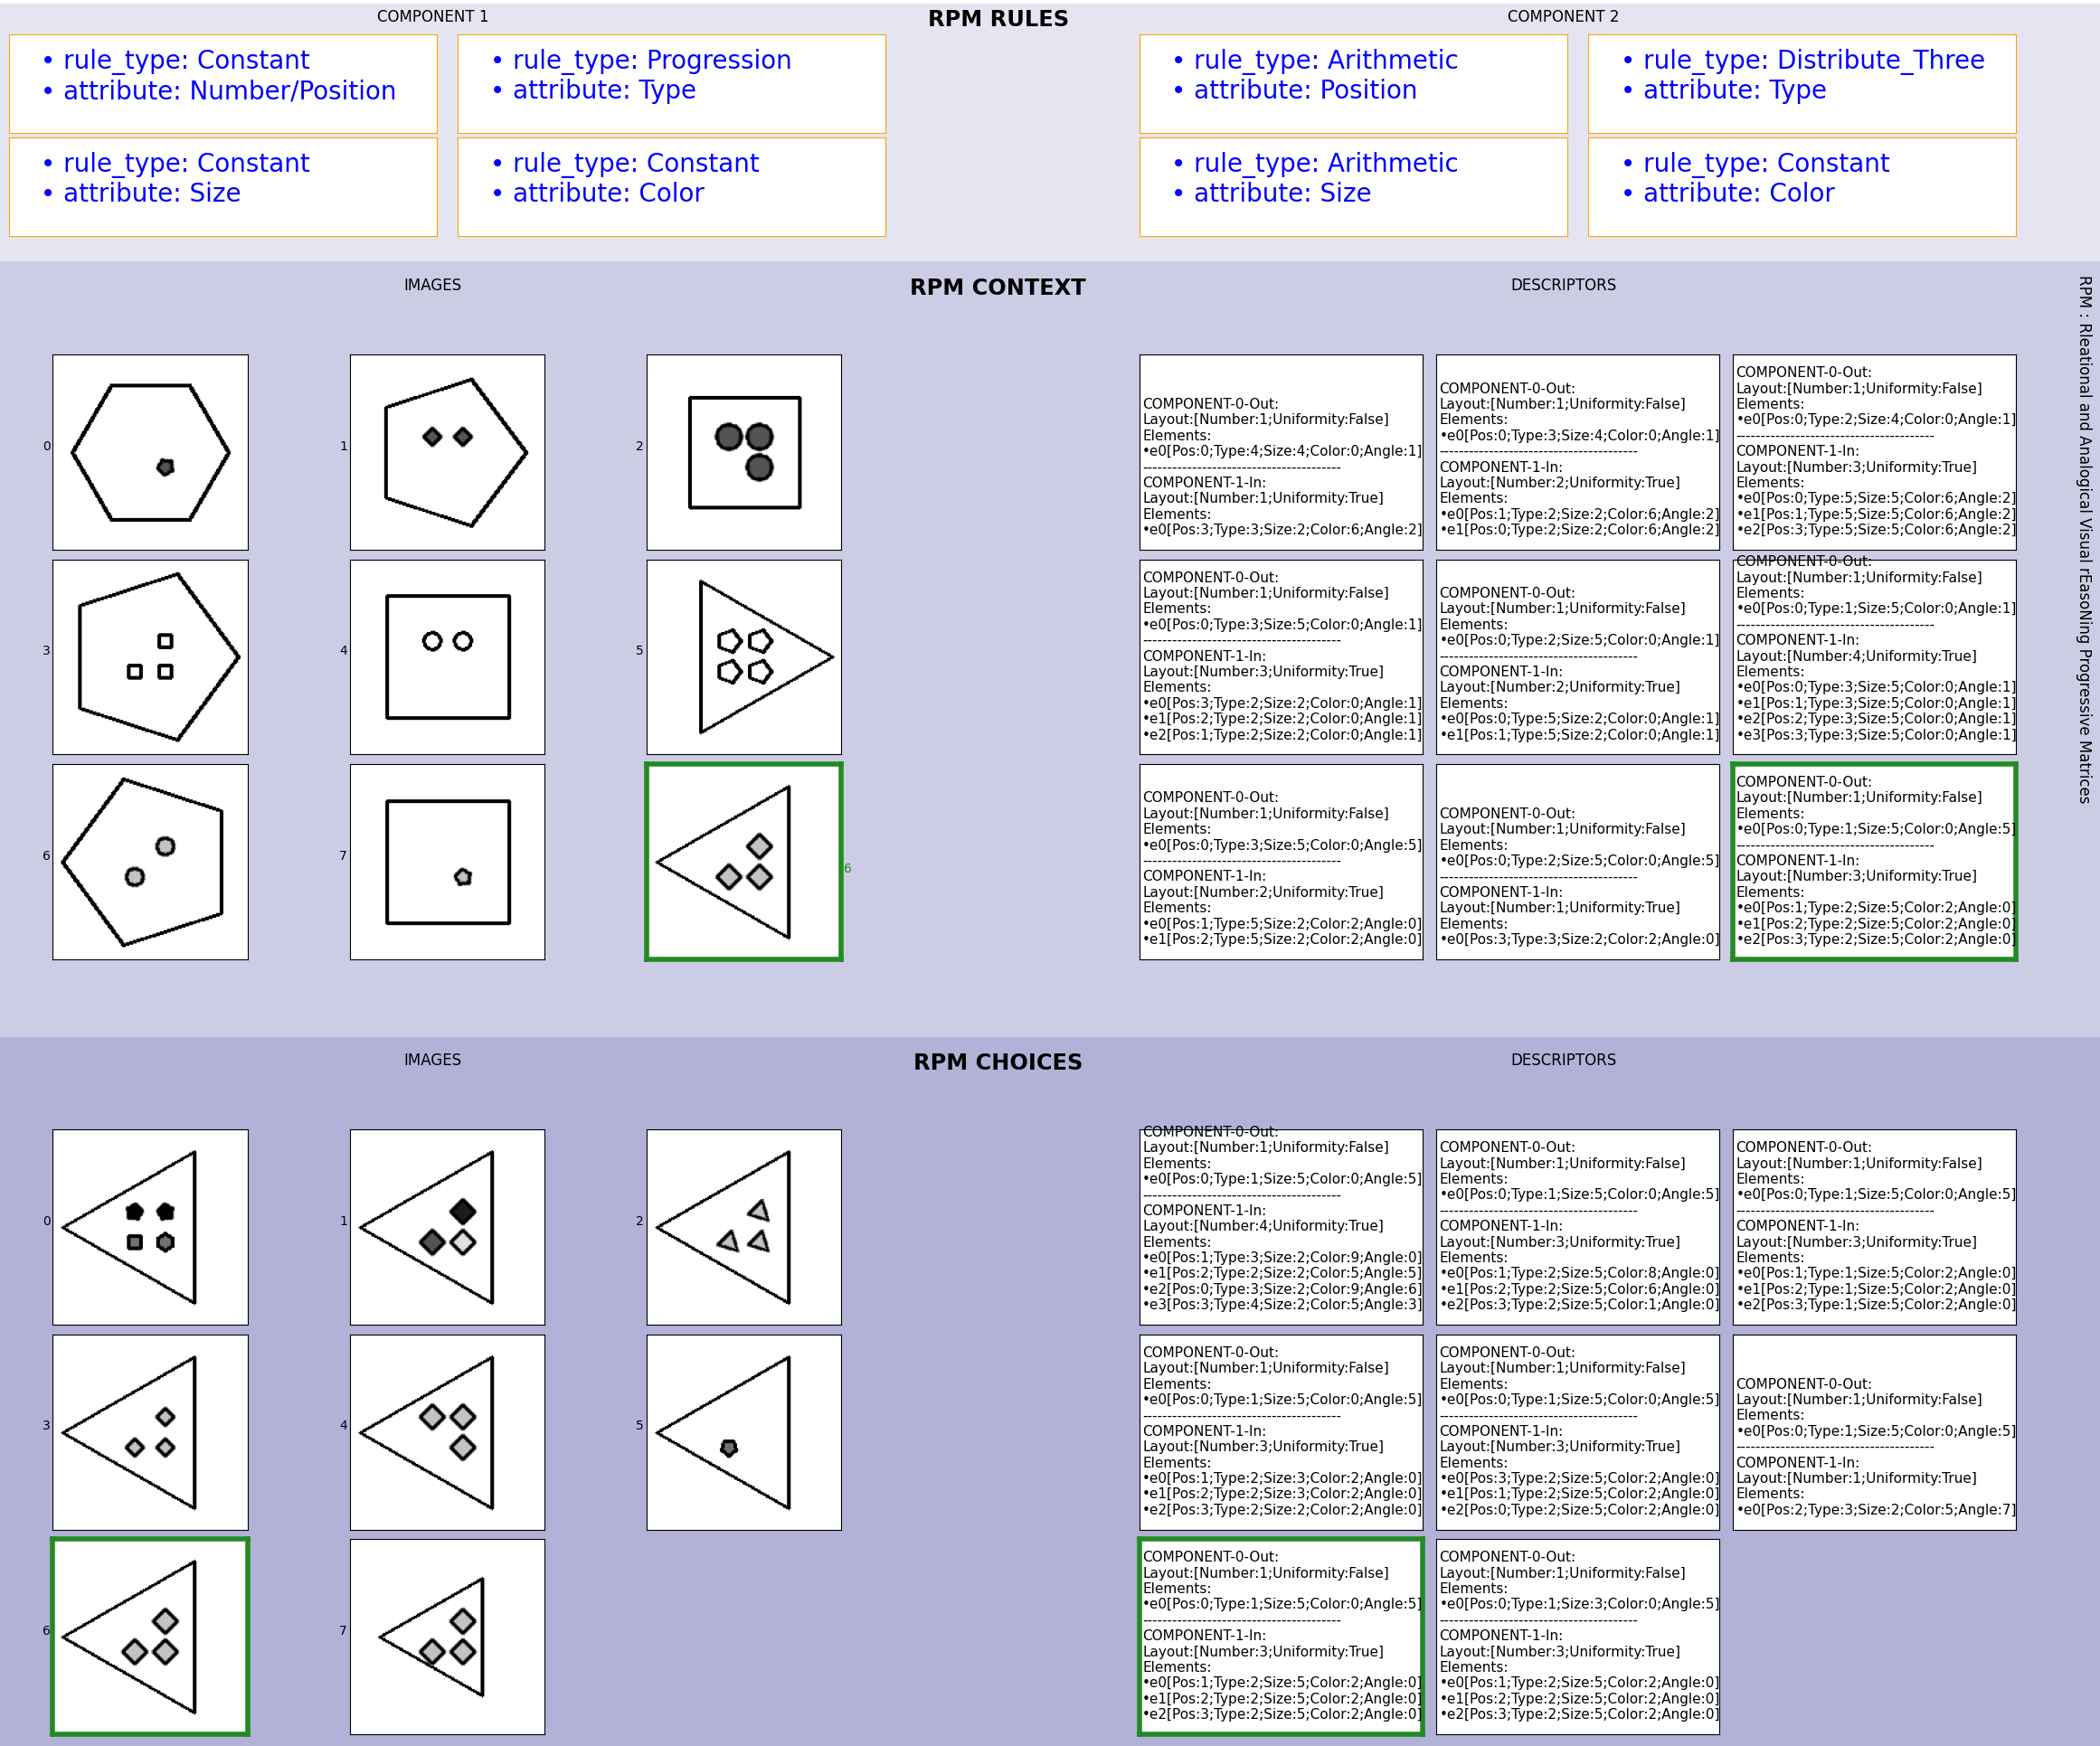

In [1]:
from hri_gnn.utils.data import readers
from hri_gnn.visualization import oracle
from hri_gnn.config.const import Configuration

problem = readers.read_config_id_problem(Configuration.IN_DISTRIBUTE_FOUR_OUT_CENTER_SINGLE.value,46)
oracle.watch_problem(problem, show_answer=True)

In [208]:
from hri_gnn.models import graph_builder

hetero_data_dict = graph_builder.build_hetero_data_batch(
    flat_bboxes, flat_panel_indices, flat_component_indices,
    flat_config_indices, flat_problem_indices, flat_batch_indices,
    model_output, include_columns=False)

hetero_data_dict[(4,67,4)]

group_by_panel_and_component: 
defaultdict(<class 'list'>, {(0, 0): [0], (0, 1): [1], (1, 0): [2], (1, 1): [3], (2, 0): [4], (2, 1): [5], (3, 0): [6], (3, 1): [7], (4, 0): [8], (4, 1): [9], (5, 0): [10], (5, 1): [11], (6, 0): [12], (6, 1): [13], (7, 0): [14], (7, 1): [15], (8, 0): [16], (8, 1): [17], (9, 0): [18], (9, 1): [19], (10, 0): [20], (10, 1): [21], (11, 0): [22], (11, 1): [23], (12, 0): [24], (12, 1): [25], (13, 0): [26], (13, 1): [27], (14, 0): [28], (14, 1): [29], (15, 0): [30], (15, 1): [31]})
group_by_panel_and_component: 
defaultdict(<class 'list'>, {(0, 0): [0], (0, 1): [1], (1, 0): [2], (1, 1): [3], (2, 0): [4], (2, 1): [5], (3, 0): [6], (3, 1): [7], (4, 0): [8], (4, 1): [9], (5, 0): [10], (5, 1): [11], (6, 0): [12], (6, 1): [13], (7, 0): [14], (7, 1): [15], (8, 0): [16], (8, 1): [17], (9, 0): [18], (9, 1): [19], (10, 0): [20], (10, 1): [21], (11, 0): [22], (11, 1): [23], (12, 0): [24], (12, 1): [25], (13, 0): [26], (13, 1): [27], (14, 0): [28], (14, 1): [29], (15, 0): 

HeteroData(
  entity_meta={
    panel_id=[57],
    component_id=[57],
    config_id=[57],
    slot_id=[57],
  },
  panel_keys=[32],
  local_idx_map={
    122=0,
    123=1,
    124=2,
    125=3,
    126=4,
    127=5,
    128=6,
    129=7,
    130=8,
    131=9,
    132=10,
    133=11,
    134=12,
    135=13,
    136=14,
    137=15,
    138=16,
    139=17,
    140=18,
    141=19,
    142=20,
    143=21,
    144=22,
    145=23,
    146=24,
    147=25,
    148=26,
    149=27,
    150=28,
    151=29,
    152=30,
    153=31,
    154=32,
    155=33,
    156=34,
    157=35,
    158=36,
    159=37,
    160=38,
    161=39,
    162=40,
    163=41,
    164=42,
    165=43,
    166=44,
    167=45,
    168=46,
    169=47,
    170=48,
    171=49,
    172=50,
    173=51,
    174=52,
    175=53,
    176=54,
    177=55,
    178=56,
  },
  panel_local_idx_map={
    (0, 0)=0,
    (0, 1)=1,
    (1, 0)=2,
    (1, 1)=3,
    (2, 0)=4,
    (2, 1)=5,
    (3, 0)=6,
    (3, 1)=7,
    (4, 0)=8,
    (4, 1)=9,
    (5,

In [154]:
"""
Visualisation d'un HeteroData construit par graph_builder.py, pour un probleme
RAVEN complet a 16 panels (0-7 = contexte, 8-15 = candidats de reponse).

Usage :
  - Sur donnees jouet : lancer directement `python visualize_graph.py`
  - Sur tes vraies donnees : appeler `visualize_hetero_data(data, out_path=...)`
    avec un objet HeteroData produit par build_hetero_data_for_problem /
    build_hetero_data_batch (voir section __main__ pour un exemple d'integration).
"""

import torch
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from hri_gnn.models import graph_builder
from hri_gnn.config.const import SLOT_TABLE, MAX_SLOTS

N_CONTEXT_PANELS = 8   # panels 0-7
N_CANDIDATES = 8        # panels 8-15


# ======================================================================
# Layout des 16 panels : matrice 3x3 (case (2,2) vide) + 8 candidats
# disposes en grille separee a droite, pour rester lisible.
# ======================================================================
def build_panel_layout():
    grid_pos = {
        0: (0, 2), 1: (1, 2), 2: (2, 2),
        3: (0, 1), 4: (1, 1), 5: (2, 1),
        6: (0, 0), 7: (1, 0),
    }
    # 8 candidats en grille 4x2, decales a droite de la matrice 3x3
    cand_cols, cand_rows = 4, 2
    x0, y0 = 4.0, 2.3
    for k, panel_id in enumerate(range(N_CONTEXT_PANELS, N_CONTEXT_PANELS + N_CANDIDATES)):
        col = k % cand_cols
        row = k // cand_cols
        grid_pos[panel_id] = (x0 + col * 1.0, y0 - row * 1.2)
    return grid_pos


# ======================================================================
# FIGURE 1 : graphe panel-component (tous les component_id presents,
# palette generee dynamiquement pour supporter plus de 2 components)
# ======================================================================
def plot_panel_graph(ax, data, grid_pos, direction='forward'):
    panel_keys = data.panel_keys  # liste de (panel_id, component_id)
    component_ids = sorted(set(c for (_, c) in panel_keys))
    palette = plt.cm.tab10.colors
    comp_color = {c: palette[i % len(palette)] for i, c in enumerate(component_ids)}
    comp_offset = {c: (i - (len(component_ids) - 1) / 2) * 0.12
                   for i, c in enumerate(component_ids)}

    G = nx.MultiDiGraph()
    node_colors, node_labels, pos = [], {}, {}

    for (p, c) in panel_keys:
        node_id = f"P{p}_c{c}"
        G.add_node(node_id)
        x, y = grid_pos[p]
        off = comp_offset[c]
        pos[node_id] = (x + off, y + off * 0.5)
        node_colors.append(comp_color[c])
        node_labels[node_id] = f"{p}.{c}"

    ei_b = data['panel', 'inter_panel_panel', 'panel'].edge_index
    ea_b = data['panel', 'inter_panel_panel', 'panel'].edge_attr
    wanted_dir = 1.0 if direction == 'forward' else -1.0
    for e in range(ei_b.shape[1]):
        if ea_b[e, 0].item() != wanted_dir:
            continue
        i, j = ei_b[0, e].item(), ei_b[1, e].item()
        p_i, c_i = panel_keys[i]
        p_j, c_j = panel_keys[j]
        G.add_edge(f"P{p_i}_c{c_i}", f"P{p_j}_c{c_j}")

    nx.draw_networkx_nodes(G, pos, node_color=node_colors, node_size=800, ax=ax, edgecolors='black')
    nx.draw_networkx_labels(G, pos, node_labels, font_size=6, ax=ax)
    nx.draw_networkx_edges(G, pos, ax=ax, edge_color='gray', alpha=0.35,
                            arrows=True, arrowsize=8, connectionstyle='arc3,rad=0.08',
                            node_size=800)

    ax.set_title(f"Graphe panel-component (16 panels)\n"
                 f"noeuds = (panel_id, component_id) - aretes b, sens {direction}",
                 fontsize=11)
    legend_handles = [mpatches.Patch(color=comp_color[c], label=f'component {c}')
                      for c in component_ids]
    ax.legend(handles=legend_handles, loc='lower left', fontsize=8)
    ax.axis('off')


# ======================================================================
# FIGURE 2 : sous-graphe entity pour un groupe de panels donne
# (ex. une ligne [0,1,2], une colonne [0,3,6], ou un groupe avec candidat)
# ======================================================================
def plot_entity_subgraph(ax, data, focus_panels, focus_component, direction='forward',
                          title_extra=""):
    entity_meta = data.entity_meta
    panel_ids_all = entity_meta['panel_id']
    comp_ids_all = entity_meta['component_id']
    slot_ids_all = entity_meta['slot_id']

    local_entity_ids = [
        i for i in range(panel_ids_all.shape[0])
        if panel_ids_all[i].item() in focus_panels and comp_ids_all[i].item() == focus_component
    ]

    def node_name(i):
        return f"e{i}(P{panel_ids_all[i].item()},s{slot_ids_all[i].item()})"

    G = nx.MultiDiGraph()
    pos, labels, colors = {}, {}, []

    col_x = {p: k * 2.2 for k, p in enumerate(focus_panels)}
    for local_i in local_entity_ids:
        p = panel_ids_all[local_i].item()
        s = slot_ids_all[local_i].item()
        node_id = node_name(local_i)
        G.add_node(node_id)
        pos[node_id] = (col_x[p] + (s % 2) * 0.5, s // 2)
        labels[node_id] = f"P{p}\nslot{s}"
        colors.append('#DD8452')

    ei_intra = data['entity', 'intra_panel', 'entity'].edge_index
    for e in range(ei_intra.shape[1]):
        i, j = ei_intra[0, e].item(), ei_intra[1, e].item()
        if i in local_entity_ids and j in local_entity_ids:
            G.add_edge(node_name(i), node_name(j), kind='intra')

    ei_a = data['entity', 'inter_panel_entity', 'entity'].edge_index
    ea_a = data['entity', 'inter_panel_entity', 'entity'].edge_attr
    wanted_dir = 1.0 if direction == 'forward' else -1.0
    for e in range(ei_a.shape[1]):
        i, j = ei_a[0, e].item(), ei_a[1, e].item()
        if i in local_entity_ids and j in local_entity_ids and ea_a[e, 0].item() == wanted_dir:
            G.add_edge(node_name(i), node_name(j), kind='inter')

    if len(G.nodes) == 0:
        ax.text(0.5, 0.5, "Aucune entite pour ce groupe/component", ha='center', va='center')
        ax.axis('off')
        return

    nx.draw_networkx_nodes(G, pos, node_color=colors, node_size=700, ax=ax, edgecolors='black')
    nx.draw_networkx_labels(G, pos, labels, font_size=6, ax=ax)

    intra_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('kind') == 'intra']
    inter_edges = [(u, v) for u, v, d in G.edges(data=True) if d.get('kind') == 'inter']

    nx.draw_networkx_edges(G, pos, edgelist=intra_edges, ax=ax, edge_color='#55A868',
                            arrows=True, arrowsize=8, connectionstyle='arc3,rad=0.15',
                            node_size=700, width=1.1)
    nx.draw_networkx_edges(G, pos, edgelist=inter_edges, ax=ax, edge_color='#C44E52',
                            arrows=True, arrowsize=8, connectionstyle='arc3,rad=0.15',
                            node_size=700, width=1.1)

    ax.set_title(f"Sous-graphe entity - component {focus_component}, "
                 f"panels {focus_panels}{title_extra}\n"
                 f"vert = intra_panel (c) | rouge = inter_panel meme slot (a), {direction}",
                 fontsize=10)
    legend_handles = [
        mpatches.Patch(color='#55A868', label='intra_panel (c)'),
        mpatches.Patch(color='#C44E52', label=f'inter_panel meme slot (a), {direction}'),
    ]
    ax.legend(handles=legend_handles, loc='upper left', fontsize=8)
    ax.axis('off')


# ======================================================================
# Fonction principale reutilisable
# ======================================================================
def visualize_hetero_data(data, out_path='/home/claude/graph_visualization.png',
                           focus_row=(0, 1, 2), focus_component=1,
                           direction='forward', print_occupation=True):
    """
    data : HeteroData produit par build_hetero_data_for_problem (16 panels attendus,
           mais fonctionne aussi avec moins de panels presents).
    focus_row : groupe de panels a detailler dans le sous-graphe entity
                (peut inclure un candidat, ex. (6, 7, 9)).
    focus_component : component_id a afficher dans le sous-graphe entity.
    direction : 'forward' ou 'backward', pour choisir quel sens d'arete afficher.
    """
    grid_pos = build_panel_layout()

    fig, axes = plt.subplots(1, 2, figsize=(22, 10))
    plot_panel_graph(axes[0], data, grid_pos, direction=direction)
    plot_entity_subgraph(axes[1], data, list(focus_row), focus_component, direction=direction)

    plt.tight_layout()
    plt.savefig(out_path, dpi=150, bbox_inches='tight')
    plt.close(fig)
    print(f"Figure sauvegardee : {out_path}")

    if print_occupation:
        entity_meta = data.entity_meta
        panel_ids_all = entity_meta['panel_id']
        comp_ids_all = entity_meta['component_id']
        present_panels = sorted(set(panel_ids_all.tolist()))
        present_components = sorted(set(comp_ids_all.tolist()))
        print("\nOccupation par panel et par component :")
        for p in present_panels:
            counts = []
            for c in present_components:
                n = sum(1 for i in range(panel_ids_all.shape[0])
                        if panel_ids_all[i].item() == p and comp_ids_all[i].item() == c)
                counts.append(f"c{c}={n}")
            label = "contexte" if p < N_CONTEXT_PANELS else "candidat"
            print(f"  panel {p:2d} ({label}): " + ", ".join(counts))



visualize_hetero_data(
        data,
        out_path='C:/Users/dhias/workspaces/these/HRI-GNN/assets/images/graph_visualization.png',
        focus_row=(3, 4, 5),
        focus_component=1,
        direction='forward',
    )

Figure sauvegardee : C:/Users/dhias/workspaces/these/HRI-GNN/assets/images/graph_visualization.png

Occupation par panel et par component :
  panel  0 (contexte): c0=1, c1=1
  panel  1 (contexte): c0=1, c1=1
  panel  2 (contexte): c0=1, c1=1
  panel  3 (contexte): c0=1, c1=1
  panel  4 (contexte): c0=1, c1=1
  panel  5 (contexte): c0=1, c1=1
  panel  6 (contexte): c0=1, c1=1
  panel  7 (contexte): c0=1, c1=1
  panel  8 (candidat): c0=1, c1=1
  panel  9 (candidat): c0=1, c1=1
  panel 10 (candidat): c0=1, c1=1
  panel 11 (candidat): c0=1, c1=1
  panel 12 (candidat): c0=1, c1=1
  panel 13 (candidat): c0=1, c1=1
  panel 14 (candidat): c0=1, c1=1
  panel 15 (candidat): c0=1, c1=1


In [189]:
import torch


EDGE_ATTR_LABELS = {
    ('entity', 'intra_panel', 'entity'): ['dx', 'dy'],
    ('entity', 'inter_panel_entity', 'entity'): None,  # genere dynamiquement (direction + deltas multiplex)
    ('panel', 'inter_panel_panel', 'panel'): ['direction', 'delta_number', 'n_common', 'n_added', 'n_removed'],
}


def _entity_label(entity_meta, local_i):
    p = entity_meta['panel_id'][local_i].item()
    c = entity_meta['component_id'][local_i].item()
    s = entity_meta['slot_id'][local_i].item()
    return f"e-{local_i}(P{p},c{c},s{s})"


def _panel_label(panel_keys, local_i):
    p, c = panel_keys[local_i]
    return f"panel-{local_i}(P{p},c{c})"


def print_edges(data, edge_type=None, max_edges=None, attr_labels=None):
    """
    data : HeteroData produit par graph_builder.py
    edge_type : tuple ('src_type','relation','dst_type') a afficher.
                Si None, affiche tous les types d'aretes presents dans data.
    max_edges : limite le nombre d'aretes affichees par type (utile pour un gros graphe).
                None = tout afficher.
    attr_labels : liste de noms de colonnes pour edge_attr (ex. ['dx','dy']).
                  Si None, utilise EDGE_ATTR_LABELS quand connu, sinon des indices generiques.
    """
    edge_types = [edge_type] if edge_type is not None else list(data.edge_types)

    entity_meta = getattr(data, 'entity_meta', None)
    panel_keys = getattr(data, 'panel_keys', None)

    for et in edge_types:
        if et not in data.edge_types:
            print(f"Type d'arete {et} absent de ce HeteroData.")
            continue

        edge_index = data[et].edge_index
        edge_attr = data[et].get('edge_attr', None)
        n_edges = edge_index.shape[1]

        print(f"\n{'='*70}")
        print(f"Type d'arete : {et}  |  {n_edges} aretes")
        print(f"{'='*70}")

        if n_edges == 0:
            print("  (aucune arete)")
            continue

        labels = attr_labels or EDGE_ATTR_LABELS.get(et)
        if labels is None and edge_attr is not None:
            labels = [f"a{k}" for k in range(edge_attr.shape[1])]

        # choix du labeliser de noeud selon le type source/destination
        src_type, _, dst_type = et
        def label_of(node_type, local_i):
            if node_type == 'entity' and entity_meta is not None:
                return _entity_label(entity_meta, local_i)
            if node_type == 'panel' and panel_keys is not None:
                return _panel_label(panel_keys, local_i)
            return f"{node_type}{local_i}"

        n_shown = n_edges if max_edges is None else min(max_edges, n_edges)
        for e in range(n_shown):
            i = edge_index[0, e].item()
            j = edge_index[1, e].item()
            src_lbl = label_of(src_type, i)
            dst_lbl = label_of(dst_type, j)

            if edge_attr is not None:
                values = edge_attr[e].tolist()
                attr_str = ", ".join(f"{lbl}={v:.3f}" for lbl, v in zip(labels, values))
                print(f"  [{e:4d}] {src_lbl:>22s} -> {dst_lbl:<22s} | {attr_str}")
            else:
                print(f"  [{e:4d}] {src_lbl:>22s} -> {dst_lbl:<22s} | (pas d'edge_attr)")

        if max_edges is not None and n_edges > max_edges:
            print(f"  ... ({n_edges - max_edges} aretes supplementaires non affichees)")



In [209]:
data

HeteroData(
  entity_meta={
    panel_id=[32],
    component_id=[32],
    config_id=[32],
    slot_id=[32],
  },
  panel_keys=[32],
  local_idx_map={
    0=0,
    1=1,
    2=2,
    3=3,
    4=4,
    5=5,
    6=6,
    7=7,
    8=8,
    9=9,
    10=10,
    11=11,
    12=12,
    13=13,
    14=14,
    15=15,
    16=16,
    17=17,
    18=18,
    19=19,
    20=20,
    21=21,
    22=22,
    23=23,
    24=24,
    25=25,
    26=26,
    27=27,
    28=28,
    29=29,
    30=30,
    31=31,
  },
  panel_local_idx_map={
    (0, 0)=0,
    (0, 1)=1,
    (1, 0)=2,
    (1, 1)=3,
    (2, 0)=4,
    (2, 1)=5,
    (3, 0)=6,
    (3, 1)=7,
    (4, 0)=8,
    (4, 1)=9,
    (5, 0)=10,
    (5, 1)=11,
    (6, 0)=12,
    (6, 1)=13,
    (7, 0)=14,
    (7, 1)=15,
    (8, 0)=16,
    (8, 1)=17,
    (9, 0)=18,
    (9, 1)=19,
    (10, 0)=20,
    (10, 1)=21,
    (11, 0)=22,
    (11, 1)=23,
    (12, 0)=24,
    (12, 1)=25,
    (13, 0)=26,
    (13, 1)=27,
    (14, 0)=28,
    (14, 1)=29,
    (15, 0)=30,
    (15, 1)=31,
  },
  

In [211]:
from hri_gnn.config.const import ENTITY_ATTRIBUTES
data = hetero_data_dict[(4,67,4)] #list(hetero_data_dict.values())[0]
# Affiche toutes les aretes intra_panel (peu nombreuses, edge_attr = [dx, dy])
print_edges(data, edge_type=('entity', 'intra_panel', 'entity'))
# Affiche seulement les 10 premieres aretes panel-panel (edge_attr nomme)
print_edges(data, edge_type=('panel', 'inter_panel_panel', 'panel'), max_edges=None)
# Affiche seulement les 10 premieres aretes entity inter_panel
# (edge_attr = [direction, delta_type(6), delta_size(6), delta_color(9), delta_angle(8)])
labels_a = ['direction'] + [f"type_{k}" for k in range(len(ENTITY_ATTRIBUTES['type']))] \
                         + [f"size_{k}" for k in range(len(ENTITY_ATTRIBUTES['size']))] \
                         + [f"color_{k}" for k in range(len(ENTITY_ATTRIBUTES['color']))] \
                         + [f"angle_{k}" for k in range(len(ENTITY_ATTRIBUTES['angle']))]
print_edges(data, edge_type=('entity', 'inter_panel_entity', 'entity'), max_edges=None, attr_labels=labels_a)


Type d'arete : ('entity', 'intra_panel', 'entity')  |  80 aretes
  [   0]          e-1(P0,c1,s3) -> e-2(P0,c1,s1)          | dx=-0.160, dy=0.000
  [   1]          e-2(P0,c1,s1) -> e-1(P0,c1,s3)          | dx=0.160, dy=-0.000
  [   2]          e-1(P0,c1,s3) -> e-3(P0,c1,s2)          | dx=0.000, dy=-0.160
  [   3]          e-3(P0,c1,s2) -> e-1(P0,c1,s3)          | dx=-0.000, dy=0.160
  [   4]          e-2(P0,c1,s1) -> e-3(P0,c1,s2)          | dx=0.160, dy=-0.160
  [   5]          e-3(P0,c1,s2) -> e-2(P0,c1,s1)          | dx=-0.160, dy=0.160
  [   6]          e-7(P2,c1,s2) -> e-8(P2,c1,s1)          | dx=-0.160, dy=0.160
  [   7]          e-8(P2,c1,s1) -> e-7(P2,c1,s2)          | dx=0.160, dy=-0.160
  [   8]          e-7(P2,c1,s2) -> e-9(P2,c1,s0)          | dx=-0.160, dy=0.000
  [   9]          e-9(P2,c1,s0) -> e-7(P2,c1,s2)          | dx=0.160, dy=-0.000
  [  10]          e-7(P2,c1,s2) -> e-10(P2,c1,s3)         | dx=0.000, dy=0.160
  [  11]         e-10(P2,c1,s3) -> e-7(P2,c1,s2)       

In [181]:
hetero_data_dict

{(6,
  47,
  0): HeteroData(
   entity_meta={
     panel_id=[32],
     component_id=[32],
     config_id=[32],
     slot_id=[32],
   },
   panel_keys=[32],
   local_idx_map={
     0=0,
     1=1,
     2=2,
     3=3,
     4=4,
     5=5,
     6=6,
     7=7,
     8=8,
     9=9,
     10=10,
     11=11,
     12=12,
     13=13,
     14=14,
     15=15,
     16=16,
     17=17,
     18=18,
     19=19,
     20=20,
     21=21,
     22=22,
     23=23,
     24=24,
     25=25,
     26=26,
     27=27,
     28=28,
     29=29,
     30=30,
     31=31,
   },
   panel_local_idx_map={
     (0, 0)=0,
     (0, 1)=1,
     (1, 0)=2,
     (1, 1)=3,
     (2, 0)=4,
     (2, 1)=5,
     (3, 0)=6,
     (3, 1)=7,
     (4, 0)=8,
     (4, 1)=9,
     (5, 0)=10,
     (5, 1)=11,
     (6, 0)=12,
     (6, 1)=13,
     (7, 0)=14,
     (7, 1)=15,
     (8, 0)=16,
     (8, 1)=17,
     (9, 0)=18,
     (9, 1)=19,
     (10, 0)=20,
     (10, 1)=21,
     (11, 0)=22,
     (11, 1)=23,
     (12, 0)=24,
     (12, 1)=25,
     (13, 0)=26,
 